In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
# Leer contenio del archivo
df = pd.read_csv("../CSVs/datosMortalidadOaxaca.csv")

print(df)

   anio  total_defunciones  tasa_Mortalidad  \
0  2015              23900            592.1   
1  2016              24500            601.5   
2  2017              25100            610.8   
3  2018              25800            622.4   
4  2019              26400            631.0   
5  2020              34204            815.3   
6  2021              39282            943.0   
7  2022              29100            694.0   
8  2023              28400            672.0   
9  2024              25600            602.0   

                                            Contexto  
0  Mortalidad bajo parámetros promedio e históricos.  
1   Ligero incremento por padecimientos del corazón.  
2                   Estabilidad demográfica estatal.  
3  Incremento paulatino por por enfermedades crón...  
4  Último año de comportamiento habitual previo a...  
5  Inicio de la pandemia de COVID-19: exceso de m...  
6  Pico histórico de mortalidad en Oaxaca (COVD-1...  
7  Descenso general tras el avance de la v

In [3]:
media_def = df['total_defunciones'].mean()

print(media_def)

28228.6


In [4]:
media_anio = df['anio'].mean()
print(media_anio)

2019.5


In [5]:
anio_menos_media = df['anio'] - media_anio
print(anio_menos_media)

0   -4.5
1   -3.5
2   -2.5
3   -1.5
4   -0.5
5    0.5
6    1.5
7    2.5
8    3.5
9    4.5
Name: anio, dtype: float64


In [6]:
media_tasa = df['tasa_Mortalidad'].mean()
print(media_tasa)

678.4100000000001


In [7]:
tasa_menos_media = df['tasa_Mortalidad'] - media_tasa
print(tasa_menos_media)

0    -86.31
1    -76.91
2    -67.61
3    -56.01
4    -47.41
5    136.89
6    264.59
7     15.59
8     -6.41
9    -76.41
Name: tasa_Mortalidad, dtype: float64


In [8]:
multiplicacion = anio_menos_media * tasa_menos_media
print(multiplicacion)

0    388.395
1    269.185
2    169.025
3     84.015
4     23.705
5     68.445
6    396.885
7     38.975
8    -22.435
9   -343.845
dtype: float64


In [9]:
suma_multi = np.sum(multiplicacion)
print(suma_multi)

1072.35


In [10]:
cuadrado = np.power(anio_menos_media, 2)
print(cuadrado)

0    20.25
1    12.25
2     6.25
3     2.25
4     0.25
5     0.25
6     2.25
7     6.25
8    12.25
9    20.25
Name: anio, dtype: float64


In [11]:
suma_cuadrado = np.sum(cuadrado)
print(suma_cuadrado)

82.5


In [12]:
m = suma_multi / suma_cuadrado

c = media_tasa - (m * media_anio)

print("m =", m, "\nc =", c)
print(f"\nRecta de regresión: y = {m:.4f}x + ({c:.4f})")

m = 12.998181818181816 
c = -25571.41818181818

Recta de regresión: y = 12.9982x + (-25571.4182)


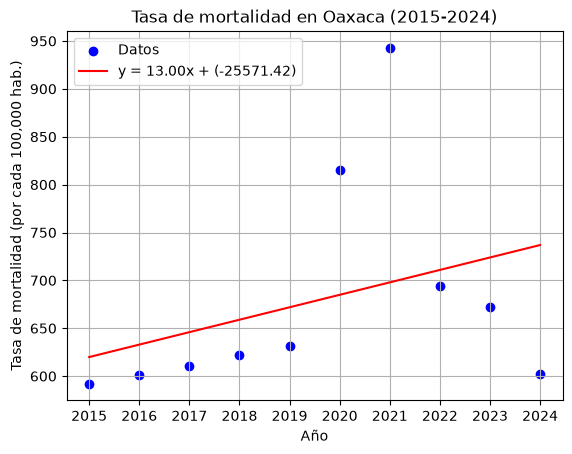

In [13]:
y_recta = (m * df['anio']) + c

plt.scatter(df['anio'], df['tasa_Mortalidad'], color='blue', label='Datos')
plt.plot(df['anio'], y_recta, color='red', label=f'y = {m:.2f}x + ({c:.2f})')
plt.title('Tasa de mortalidad en Oaxaca (2015-2024)')
plt.xlabel('Año')
plt.ylabel('Tasa de mortalidad (por cada 100,000 hab.)')
plt.xticks(df['anio'])
plt.legend()
plt.grid(True)
plt.show()

In [14]:
y_2030 = (m * 2030) + c
y_2035 = (m * 2035) + c

print("Tasa de mortalidad estimada en 2030:", y_2030)
print("Tasa de mortalidad estimada en 2035:", y_2035)

Tasa de mortalidad estimada en 2030: 814.8909090909074
Tasa de mortalidad estimada en 2035: 879.8818181818169
